In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)

# Load Iris dataset
iris = load_iris()

X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target

print("Dataset Shape:", X.shape)

print("\nFirst Five Rows:")
print(X.head())

print("\nDataset Description:")
print(X.describe())

print("\nMissing Values:")
print(X.isnull().sum().sum())

print("\nTarget Classes:")
print(iris.target_names)

Dataset Shape: (150, 4)

First Five Rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Dataset Description:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000 

In [2]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original Data Shape:", X.shape)
print("Scaled Data Shape:", X_scaled.shape)

print("\nFirst Five Scaled Rows:")
print(X_scaled[:5])

Original Data Shape: (150, 4)
Scaled Data Shape: (150, 4)

First Five Scaled Rows:
[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


In [3]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

print("K-Means Cluster Labels:")
print(kmeans_labels)

print("\nCluster Centers:")
print(kmeans.cluster_centers_)

print("\nNumber of Clusters:")
print(len(set(kmeans_labels)))

K-Means Cluster Labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]

Cluster Centers:
[[-0.05021989 -0.88337647  0.34773781  0.2815273 ]
 [-1.01457897  0.85326268 -1.30498732 -1.25489349]
 [ 1.13597027  0.08842168  0.99615451  1.01752612]]

Number of Clusters:
3


In [4]:
agg_model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

agg_labels = agg_model.fit_predict(X_scaled)

print("Agglomerative Cluster Labels:")
print(agg_labels)

print("\nNumber of Clusters:")
print(len(set(agg_labels)))

Agglomerative Cluster Labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 2 1 1 1 1 1 1 1 1 0 0 0 2 0 2 0 2 0 2 2 0 2 0 2 0 2 2 2 2 0 0 0 0
 0 0 0 0 0 2 2 2 2 0 2 0 0 2 2 2 2 0 2 2 2 2 2 0 2 2 0 0 0 0 0 0 2 0 0 0 0
 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]

Number of Clusters:
3


In [5]:
dbscan = DBSCAN(
    eps=0.8,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_scaled)

print("DBSCAN Cluster Labels:")
print(dbscan_labels)

print("\nNumber of Clusters:")
print(len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0))

print("\nNoise Points:", list(dbscan_labels).count(-1))

DBSCAN Cluster Labels:
[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1  0  0  0  0  0  0
  0  0  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1  1  1  1 -1  1  1
  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1]

Number of Clusters:
2

Noise Points: 4


In [6]:
clustering_results = {
    "K-Means": kmeans_labels,
    "Agglomerative": agg_labels,
    "DBSCAN": dbscan_labels
}

for name, labels in clustering_results.items():
    unique_clusters = set(labels)
    n_clusters = len(unique_clusters - {-1})

    print("\n", name)

    if n_clusters >= 2 and n_clusters < len(labels):
        print("Silhouette Score:", silhouette_score(X_scaled, labels))
        print("Davies-Bouldin Index:", davies_bouldin_score(X_scaled, labels))
    else:
        print("Evaluation not possible: insufficient clusters.")


 K-Means
Silhouette Score: 0.45994823920518635
Davies-Bouldin Index: 0.8335949464754338

 Agglomerative
Silhouette Score: 0.4466890410285909
Davies-Bouldin Index: 0.8034665302876753

 DBSCAN
Silhouette Score: 0.5216965052515835
Davies-Bouldin Index: 1.9432005358011466


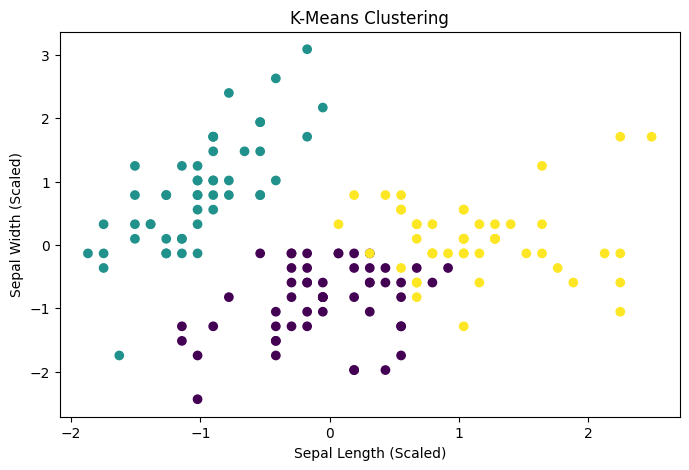

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmeans_labels,
    cmap="viridis"
)

plt.xlabel("Sepal Length (Scaled)")
plt.ylabel("Sepal Width (Scaled)")
plt.title("K-Means Clustering")

plt.show()

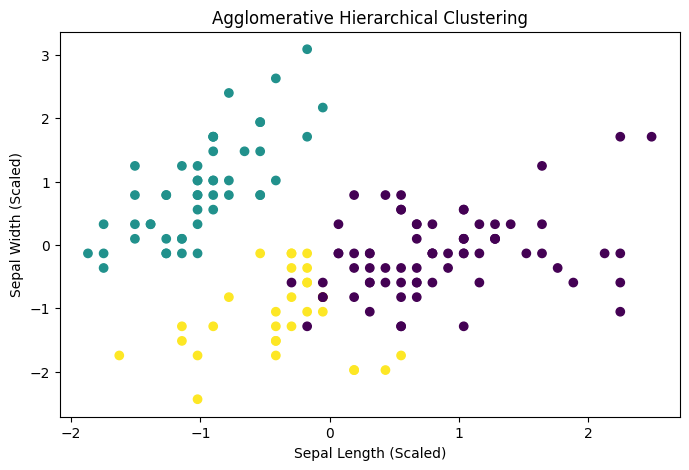

In [8]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=agg_labels,
    cmap="viridis"
)

plt.xlabel("Sepal Length (Scaled)")
plt.ylabel("Sepal Width (Scaled)")
plt.title("Agglomerative Hierarchical Clustering")

plt.show()

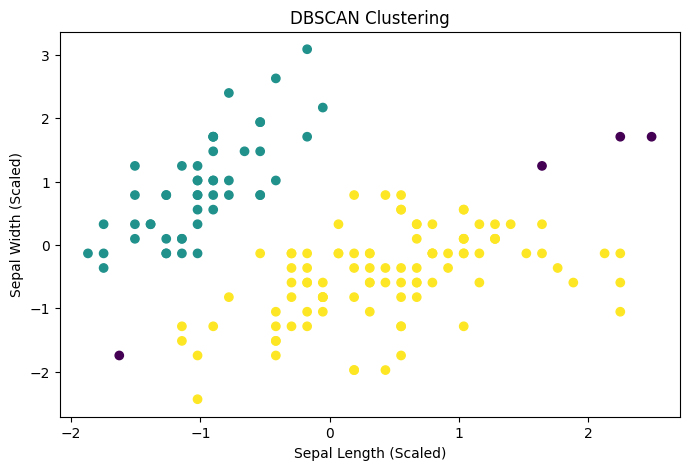

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=dbscan_labels,
    cmap="viridis"
)

plt.xlabel("Sepal Length (Scaled)")
plt.ylabel("Sepal Width (Scaled)")
plt.title("DBSCAN Clustering")

plt.show()

In [10]:
comparison = []

for name, labels in clustering_results.items():
    n_clusters = len(set(labels) - {-1})

    if n_clusters >= 2 and n_clusters < len(labels):
        silhouette = silhouette_score(X_scaled, labels)
        db_index = davies_bouldin_score(X_scaled, labels)
    else:
        silhouette = np.nan
        db_index = np.nan

    comparison.append({
        "Algorithm": name,
        "Number of Clusters": n_clusters,
        "Silhouette Score": silhouette,
        "Davies-Bouldin Index": db_index
    })

comparison_df = pd.DataFrame(comparison)

print(comparison_df)

       Algorithm  Number of Clusters  Silhouette Score  Davies-Bouldin Index
0        K-Means                   3          0.459948              0.833595
1  Agglomerative                   3          0.446689              0.803467
2         DBSCAN                   2          0.521697              1.943201


In [11]:
print("Best Algorithm Based on Silhouette Score:")

valid_results = comparison_df.dropna(subset=["Silhouette Score"])

if not valid_results.empty:
    best_silhouette = valid_results.loc[
        valid_results["Silhouette Score"].idxmax()
    ]
    print(best_silhouette)

print("\nBest Algorithm Based on Davies-Bouldin Index:")

valid_results = comparison_df.dropna(subset=["Davies-Bouldin Index"])

if not valid_results.empty:
    best_db = valid_results.loc[
        valid_results["Davies-Bouldin Index"].idxmin()
    ]
    print(best_db)

Best Algorithm Based on Silhouette Score:
Algorithm                 DBSCAN
Number of Clusters             2
Silhouette Score        0.521697
Davies-Bouldin Index    1.943201
Name: 2, dtype: object

Best Algorithm Based on Davies-Bouldin Index:
Algorithm               Agglomerative
Number of Clusters                  3
Silhouette Score             0.446689
Davies-Bouldin Index         0.803467
Name: 1, dtype: object
